In [14]:
!pip -q install "autogluon.tabular" "gensim>=4.3.3" "transformers" "accelerate"

In [17]:
!pip install --upgrade --force-reinstall "numpy==2.2.6" "seaborn==0.13.2"

  Using cached numpy-2.2.6-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
  Using cached pandas-3.0.6-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.1/130.1 kB 5.5 MB/s eta 0:00:00
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
Using cached numpy-2.2.6-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 17.7 MB/s eta 0:00:00
Using cached matplotlib-3.11.2-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.9 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 107.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 384.7/384.7 kB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Seaborn version:", sns.__version__)

print("\nAll imports successful!")

NumPy version: 2.2.6
Pandas version: 3.0.6
Seaborn version: 0.13.2

All imports successful!


In [2]:
import os
import re
import ast
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from gensim.models import Word2Vec, FastText

from transformers import AutoTokenizer, AutoModel

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)
from sklearn.metrics.pairwise import cosine_similarity

from autogluon.tabular import TabularPredictor

import torch

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# Upload your dataset
from google.colab import files

uploaded = files.upload()

csv_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError("Please upload a CSV dataset.")

FILE_PATH = csv_files[0]

df = pd.read_csv(FILE_PATH)

print("\nDataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

display(df.head())

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


Saving resume_data_for_ranking.csv to resume_data_for_ranking.csv

Dataset loaded successfully.
Dataset shape: (9544, 35)

Columns:
['address', 'career_objective', 'skills', 'educational_institution_name', 'degree_names', 'passing_years', 'educational_results', 'result_types', 'major_field_of_studies', 'professional_company_names', 'company_urls', 'start_dates', 'end_dates', 'related_skils_in_job', 'positions', 'locations', 'responsibilities', 'extra_curricular_activity_types', 'extra_curricular_organization_names', 'extra_curricular_organization_links', 'role_positions', 'languages', 'proficiency_levels', 'certification_providers', 'certification_skills', 'online_links', 'issue_dates', 'expiry_dates', 'job_position_name', 'educationaL_requirements', 'experiencere_requirement', 'age_requirement', 'responsibilities.1', 'skills_required', 'matched_score']


,address,career_objective,skills,educational_institution_name,degree_names,passing_years,educational_results,result_types,major_field_of_studies,professional_company_names,...,online_links,issue_dates,expiry_dates,job_position_name,educationaL_requirements,experiencere_requirement,age_requirement,responsibilities.1,skills_required,matched_score
0,NaN,Big data analytics working and database wareho...,"['Big Data', 'Hadoop', 'Hive', 'Python', 'Mapr...",['The Amity School of Engineering & Technology...,['B.Tech'],['2019'],['N/A'],[None],['Electronics'],['Coca-COla'],...,NaN,NaN,NaN,Senior Software Engineer,B.Sc in Computer Science & Engineering from a ...,At least 1 year,NaN,Technical Support\nTroubleshooting\nCollaborat...,NaN,0.850000
1,NaN,Fresher looking to join as a data analyst and ...,"['Data Analysis', 'Data Analytics', 'Business ...","['Delhi University - Hansraj College', 'Delhi ...","['B.Sc (Maths)', 'M.Sc (Science) (Statistics)']","['2015', '2018']","['N/A', 'N/A']","['N/A', 'N/A']","['Mathematics', 'Statistics']",['BIB Consultancy'],...,NaN,NaN,NaN,Machine Learning (ML) Engineer,M.Sc in Computer Science & Engineering or in a...,At least 5 year(s),NaN,Machine Learning Leadership\nCross-Functional ...,NaN,0.750000
2,NaN,NaN,"['Software Development', 'Machine Learning', '...","['Birla Institute of Technology (BIT), Ranchi']",['B.Tech'],['2018'],['N/A'],['N/A'],['Electronics/Telecommunication'],['Axis Bank Limited'],...,NaN,NaN,NaN,"Executive/ Senior Executive- Trade Marketing, ...",Master of Business Administration (MBA),At least 3 years,NaN,"Trade Marketing Executive\nBrand Visibility, S...",Brand Promotion\nCampaign Management\nField Su...,0.416667
3,NaN,To obtain a position in a fast-paced business ...,"['accounts payables', 'accounts receivables', ...","['Martinez Adult Education, Business Training ...",['Computer Applications Specialist Certificate...,['2008'],[None],[None],['Computer Applications'],"['Company Name ï¼ City , State', 'Company Name...",...,NaN,NaN,NaN,Business Development Executive,Bachelor/Honors,1 to 3 years,Age 22 to 30 years,Apparel Sourcing\nQuality Garment Sourcing\nRe...,Fast typing skill\nIELTSInternet browsing & on...,0.760000
4,NaN,Professional accountant with an outstanding wo...,"['Analytical reasoning', 'Compliance testing k...",['Kent State University'],['Bachelor of Business Administration'],[None],['3.84'],[None],['Accounting'],"['Company Name', 'Company Name', 'Company Name...",...,[None],[None],"['February 15, 2021']",Senior iOS Engineer,Bachelor of Science (BSc) in Computer Science,At least 4 years,NaN,iOS Lifecycle\nRequirement Analysis\nNative Fr...,iOS\niOS App Developer\niOS Application Develo...,0.650000


In [3]:
TARGET = "matched_score"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' is missing from the dataset."
    )

# Convert target to numeric
df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

df = df.dropna(
    subset=[TARGET]
).reset_index(drop=True)

# Remove infinite target values
df = df[
    np.isfinite(df[TARGET])
].reset_index(drop=True)


def clean_text(value):

    if pd.isna(value):
        return ""

    text = str(value)

    # Convert list-like strings to readable text
    try:
        parsed = ast.literal_eval(text)

        if isinstance(parsed, (list, tuple, set)):
            text = " ".join(
                str(item) for item in parsed
            )

    except (ValueError, SyntaxError):
        pass

    text = text.lower()

    # Preserve letters, numbers and useful text boundaries
    text = re.sub(
        r"[^a-z0-9\s+#.]",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


print("Records after target cleaning:", len(df))
print("Missing target values:", df[TARGET].isna().sum())

print("\nTarget distribution:")
print(df[TARGET].describe())

Records after target cleaning: 9544
Missing target values: 0

Target distribution:
count    9544.000000
mean        0.660831
std         0.167040
min         0.000000
25%         0.583333
50%         0.683333
75%         0.793333
max         0.970000
Name: matched_score, dtype: float64


In [4]:
candidate_columns = [
    "career_objective",
    "skills",
    "degree_names",
    "major_field_of_studies",
    "positions",
    "responsibilities",
    "certification_skills"
]

job_columns = [
    "job_position_name",
    "educationaL_requirements",
    "experiencere_requirement",
    "responsibilities.1",
    "skills_required"
]

candidate_columns = [
    col for col in candidate_columns
    if col in df.columns
]

job_columns = [
    col for col in job_columns
    if col in df.columns
]

if not candidate_columns:
    raise ValueError(
        "No candidate text columns were found."
    )

if not job_columns:
    raise ValueError(
        "No job-description columns were found."
    )


for col in set(candidate_columns + job_columns):
    df[col] = df[col].apply(clean_text)


df["candidate_text"] = (
    df[candidate_columns]
    .fillna("")
    .agg(" ".join, axis=1)
    .str.strip()
)

df["job_text"] = (
    df[job_columns]
    .fillna("")
    .agg(" ".join, axis=1)
    .str.strip()
)

df["combined_text"] = (
    df["candidate_text"]
    + " "
    + df["job_text"]
).str.strip()


# Remove records with no usable text on either side
valid_text = (
    df["candidate_text"].str.len().gt(0)
    & df["job_text"].str.len().gt(0)
)

df = df.loc[valid_text].reset_index(drop=True)

print("Candidate columns:", candidate_columns)
print("Job columns:", job_columns)

print("\nUsable records:", len(df))

display(
    df[
        [
            "candidate_text",
            "job_text",
            TARGET
        ]
    ].head(3)
)

Candidate columns: ['career_objective', 'skills', 'degree_names', 'major_field_of_studies', 'positions', 'responsibilities', 'certification_skills']
Job columns: ['job_position_name', 'educationaL_requirements', 'experiencere_requirement', 'responsibilities.1', 'skills_required']

Usable records: 9544


,candidate_text,job_text,matched_score
0,big data analytics working and database wareho...,senior software engineer b.sc in computer scie...,0.850000
1,fresher looking to join as a data analyst and ...,machine learning ml engineer m.sc in computer ...,0.750000
2,software development machine learning deep lea...,executive senior executive trade marketing hyg...,0.416667


In [6]:
def extract_years(text):

    text = str(text).lower()

    match = re.search(
        r"(\d+(?:\.\d+)?)\s*year",
        text
    )

    if match:
        return float(match.group(1))

    return 0.0


def calculate_candidate_experience(row):

    start_text = str(
        row.get("start_dates", "")
    )

    end_text = str(
        row.get("end_dates", "")
    )

    start_years = re.findall(
        r"\b(?:19|20)\d{2}\b",
        start_text
    )

    end_years = re.findall(
        r"\b(?:19|20)\d{2}\b",
        end_text
    )

    if not start_years:
        return 0.0

    start_year = int(start_years[0])

    # Do not interpret "Till Date" as a literal date.
    # If no end year is present, treat the role as current.
    if end_years:
        end_year = int(end_years[-1])
    else:
        end_year = pd.Timestamp.now().year

    return max(
        0.0,
        float(end_year - start_year)
    )


if "experiencere_requirement" in df.columns:

    df["required_experience"] = (
        df["experiencere_requirement"]
        .apply(extract_years)
    )

else:
    df["required_experience"] = 0.0


df["candidate_experience"] = df.apply(
    calculate_candidate_experience,
    axis=1
)


df["experience_adequacy"] = np.where(
    df["required_experience"] > 0,

    np.minimum(
        df["candidate_experience"]
        / df["required_experience"],
        1.0
    ),

    1.0
)


print("Experience features created.")

display(
    df[
        [
            "candidate_experience",
            "required_experience",
            "experience_adequacy"
        ]
    ].head()
)

Experience features created.


,candidate_experience,required_experience,experience_adequacy
0,7.0,1.0,1.0
1,7.0,5.0,1.0
2,8.0,3.0,1.0
3,0.0,3.0,0.0
4,0.0,4.0,0.0


In [7]:
train_indices, test_indices = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=SEED
)

train_df = (
    df.iloc[train_indices]
    .reset_index(drop=True)
)

test_df = (
    df.iloc[test_indices]
    .reset_index(drop=True)
)

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print(
    "Training percentage:",
    round(len(train_df) / len(df) * 100, 2),
    "%"
)

print(
    "Testing percentage:",
    round(len(test_df) / len(df) * 100, 2),
    "%"
)

Training records: 7635
Testing records: 1909
Training percentage: 80.0 %
Testing percentage: 20.0 %


In [8]:
def tokenize(text):
    return re.findall(
        r"[a-z0-9+#.]+",
        str(text).lower()
    )


word2vec_corpus = []

for text in train_df["candidate_text"]:
    word2vec_corpus.append(tokenize(text))

for text in train_df["job_text"]:
    word2vec_corpus.append(tokenize(text))


word2vec_model = Word2Vec(
    sentences=word2vec_corpus,
    vector_size=100,
    window=5,
    min_count=1,
    workers=2,
    sg=0,
    epochs=20,
    seed=SEED
)

print("Word2Vec training complete.")

print(
    "Vocabulary size:",
    len(word2vec_model.wv)
)

Word2Vec training complete.
Vocabulary size: 3729


In [9]:
W2V_DIM = 100


def word2vec_embedding(text):

    tokens = tokenize(text)

    vectors = [
        word2vec_model.wv[word]
        for word in tokens
        if word in word2vec_model.wv
    ]

    if not vectors:
        return np.zeros(
            W2V_DIM,
            dtype=np.float32
        )

    return np.mean(
        vectors,
        axis=0
    ).astype(np.float32)


def build_word2vec_features(data):

    candidate_vectors = np.vstack(
        data["candidate_text"].apply(
            word2vec_embedding
        ).values
    )

    job_vectors = np.vstack(
        data["job_text"].apply(
            word2vec_embedding
        ).values
    )

    return (
        candidate_vectors,
        job_vectors
    )


w2v_candidate_train, w2v_job_train = (
    build_word2vec_features(train_df)
)

w2v_candidate_test, w2v_job_test = (
    build_word2vec_features(test_df)
)

print(
    "Word2Vec candidate embeddings:",
    w2v_candidate_train.shape
)

print(
    "Word2Vec job embeddings:",
    w2v_job_train.shape
)

Word2Vec candidate embeddings: (7635, 100)
Word2Vec job embeddings: (7635, 100)


In [11]:
fasttext_model = FastText(
    sentences=word2vec_corpus,
    vector_size=100,
    window=5,
    min_count=1,
    workers=2,
    sg=0,
    min_n=3,
    max_n=6,
    epochs=20,
    seed=SEED
)

print("FastText training complete.")

print(
    "FastText vocabulary size:",
    len(fasttext_model.wv)
)

FastText training complete.
FastText vocabulary size: 3729


In [12]:
FASTTEXT_DIM = 100


def fasttext_embedding(text):

    tokens = tokenize(text)

    if not tokens:
        return np.zeros(
            FASTTEXT_DIM,
            dtype=np.float32
        )

    vectors = [
        fasttext_model.wv[word]
        for word in tokens
    ]

    return np.mean(
        vectors,
        axis=0
    ).astype(np.float32)


def build_fasttext_features(data):

    candidate_vectors = np.vstack(
        data["candidate_text"].apply(
            fasttext_embedding
        ).values
    )

    job_vectors = np.vstack(
        data["job_text"].apply(
            fasttext_embedding
        ).values
    )

    return (
        candidate_vectors,
        job_vectors
    )


ft_candidate_train, ft_job_train = (
    build_fasttext_features(train_df)
)

ft_candidate_test, ft_job_test = (
    build_fasttext_features(test_df)
)

print(
    "FastText candidate embeddings:",
    ft_candidate_train.shape
)

print(
    "FastText job embeddings:",
    ft_job_train.shape
)

FastText candidate embeddings: (7635, 100)
FastText job embeddings: (7635, 100)


In [13]:
MODEL_NAME = "FacebookAI/roberta-base"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Loading RoBERTa...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

roberta_model = AutoModel.from_pretrained(
    MODEL_NAME
)

roberta_model = roberta_model.to(device)
roberta_model.eval()

print("RoBERTa loaded successfully.")

Device: cuda
Loading RoBERTa...


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa loaded successfully.


In [14]:
ROBERTA_BATCH_SIZE = 16
MAX_LENGTH = 256


@torch.inference_mode()
def roberta_embeddings(texts):

    all_embeddings = []

    for start in range(
        0,
        len(texts),
        ROBERTA_BATCH_SIZE
    ):

        batch_texts = texts[
            start:
            start + ROBERTA_BATCH_SIZE
        ]

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        outputs = roberta_model(**encoded)

        token_embeddings = (
            outputs.last_hidden_state
        )

        attention_mask = (
            encoded["attention_mask"]
            .unsqueeze(-1)
            .to(token_embeddings.dtype)
        )

        summed_embeddings = (
            token_embeddings
            * attention_mask
        ).sum(dim=1)

        token_counts = attention_mask.sum(
            dim=1
        ).clamp(min=1)

        sentence_embeddings = (
            summed_embeddings
            / token_counts
        )

        sentence_embeddings = (
            torch.nn.functional.normalize(
                sentence_embeddings,
                p=2,
                dim=1
            )
        )

        all_embeddings.append(
            sentence_embeddings.cpu().numpy()
        )

    return np.vstack(
        all_embeddings
    ).astype(np.float32)


print("Generating training embeddings...")

roberta_candidate_train = roberta_embeddings(
    train_df["candidate_text"].tolist()
)

roberta_job_train = roberta_embeddings(
    train_df["job_text"].tolist()
)


print("Generating test embeddings...")

roberta_candidate_test = roberta_embeddings(
    test_df["candidate_text"].tolist()
)

roberta_job_test = roberta_embeddings(
    test_df["job_text"].tolist()
)


print(
    "RoBERTa candidate train shape:",
    roberta_candidate_train.shape
)

print(
    "RoBERTa job train shape:",
    roberta_job_train.shape
)

print(
    "RoBERTa candidate test shape:",
    roberta_candidate_test.shape
)

Generating training embeddings...
Generating test embeddings...
RoBERTa candidate train shape: (7635, 768)
RoBERTa job train shape: (7635, 768)
RoBERTa candidate test shape: (1909, 768)


In [15]:
def rowwise_cosine(A, B):

    numerator = np.sum(
        A * B,
        axis=1
    )

    denominator = (
        np.linalg.norm(
            A,
            axis=1
        )
        * np.linalg.norm(
            B,
            axis=1
        )
    )

    return np.divide(
        numerator,
        denominator,
        out=np.zeros_like(
            numerator,
            dtype=np.float32
        ),
        where=denominator != 0
    )


def create_similarity_features(
    w2v_candidate,
    w2v_job,
    ft_candidate,
    ft_job,
    rob_candidate,
    rob_job
):

    return pd.DataFrame({

        "word2vec_similarity": rowwise_cosine(
            w2v_candidate,
            w2v_job
        ),

        "fasttext_similarity": rowwise_cosine(
            ft_candidate,
            ft_job
        ),

        "roberta_similarity": rowwise_cosine(
            rob_candidate,
            rob_job
        )

    })


similarity_train = create_similarity_features(
    w2v_candidate_train,
    w2v_job_train,
    ft_candidate_train,
    ft_job_train,
    roberta_candidate_train,
    roberta_job_train
)

similarity_test = create_similarity_features(
    w2v_candidate_test,
    w2v_job_test,
    ft_candidate_test,
    ft_job_test,
    roberta_candidate_test,
    roberta_job_test
)

print("Similarity features created.")

display(similarity_train.head())

Similarity features created.


,word2vec_similarity,fasttext_similarity,roberta_similarity
0,0.581782,0.652300,0.976322
1,0.389508,0.527782,0.976049
2,0.389337,0.533551,0.982384
3,0.883020,0.809761,0.989097
4,0.344342,0.330390,0.974923


In [16]:
def build_ml_features(
    data,
    w2v_candidate,
    w2v_job,
    ft_candidate,
    ft_job,
    rob_candidate,
    rob_job,
    similarities
):

    feature_dict = {}

    # Word2Vec embeddings
    for i in range(w2v_candidate.shape[1]):

        feature_dict[
            f"w2v_candidate_{i}"
        ] = w2v_candidate[:, i]

        feature_dict[
            f"w2v_job_{i}"
        ] = w2v_job[:, i]


    # FastText embeddings
    for i in range(ft_candidate.shape[1]):

        feature_dict[
            f"fasttext_candidate_{i}"
        ] = ft_candidate[:, i]

        feature_dict[
            f"fasttext_job_{i}"
        ] = ft_job[:, i]


    # RoBERTa embeddings
    for i in range(rob_candidate.shape[1]):

        feature_dict[
            f"roberta_candidate_{i}"
        ] = rob_candidate[:, i]

        feature_dict[
            f"roberta_job_{i}"
        ] = rob_job[:, i]


    feature_df = pd.DataFrame(
        feature_dict
    )

    # Additional numerical features
    numerical_columns = [
        "candidate_experience",
        "required_experience",
        "experience_adequacy"
    ]

    for col in numerical_columns:

        feature_df[col] = (
            data[col]
            .fillna(0)
            .to_numpy()
        )


    # Similarity features
    similarities = similarities.reset_index(
        drop=True
    )

    feature_df = pd.concat(
        [
            feature_df.reset_index(drop=True),
            similarities
        ],
        axis=1
    )

    return feature_df


X_train = build_ml_features(
    train_df,
    w2v_candidate_train,
    w2v_job_train,
    ft_candidate_train,
    ft_job_train,
    roberta_candidate_train,
    roberta_job_train,
    similarity_train
)

X_test = build_ml_features(
    test_df,
    w2v_candidate_test,
    w2v_job_test,
    ft_candidate_test,
    ft_job_test,
    roberta_candidate_test,
    roberta_job_test,
    similarity_test
)


y_train = train_df[TARGET].reset_index(
    drop=True
)

y_test = test_df[TARGET].reset_index(
    drop=True
)


# Create the AutoGluon training table
train_data = X_train.copy()

train_data[TARGET] = y_train.to_numpy()


print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)

print(
    "Total training columns:",
    len(train_data.columns)
)

display(train_data.head())

Training feature matrix: (7635, 1942)
Testing feature matrix: (1909, 1942)
Total training columns: 1943


,w2v_candidate_0,w2v_job_0,w2v_candidate_1,w2v_job_1,w2v_candidate_2,w2v_job_2,w2v_candidate_3,w2v_job_3,w2v_candidate_4,w2v_job_4,...,roberta_job_766,roberta_candidate_767,roberta_job_767,candidate_experience,required_experience,experience_adequacy,word2vec_similarity,fasttext_similarity,roberta_similarity,matched_score
0,-0.225850,-0.370615,0.005062,-0.709934,0.131927,-0.093088,0.619222,0.834024,-0.420206,0.270128,...,-0.001738,0.000477,0.003275,0.0,6.0,0.0,0.581782,0.652300,0.976322,0.850000
1,0.239734,0.040213,-0.414378,-0.937576,0.529730,-0.152540,-0.120795,-0.864773,-0.626795,-0.096153,...,0.001192,0.001312,-0.004957,0.0,5.0,0.0,0.389508,0.527782,0.976049,0.716667
2,-1.084485,0.040213,-0.670763,-0.937576,0.774200,-0.152540,0.246138,-0.864773,-1.278581,-0.096153,...,0.001192,-0.008641,-0.004957,6.0,5.0,1.0,0.389337,0.533551,0.982384,0.350000
3,-0.381420,-0.596422,-0.968041,-1.106409,-0.530486,-0.906829,0.140167,0.056919,-0.594357,-0.164538,...,0.000500,-0.000099,0.000065,0.0,2.0,0.0,0.883020,0.809761,0.989097,0.716667
4,-1.253437,0.297603,-0.301697,-1.487089,0.965518,0.091789,-1.551418,-0.444098,-1.084246,-1.918132,...,0.002730,0.008127,-0.002242,2.0,5.0,0.4,0.344342,0.330390,0.974923,0.333333


In [17]:
MODEL_PATH = (
    "/content/resume_autogluon_embeddings"
)

predictor = TabularPredictor(
    label=TARGET,
    problem_type="regression",
    eval_metric="r2",
    path=MODEL_PATH
)

predictor.fit(
    train_data=train_data,
    presets="medium_quality",
    time_limit=600,
    num_cpus=2,
    num_gpus=1 if torch.cuda.is_available() else 0
)

print("\nAutoGluon training completed.")

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.15
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cu130
CUDA Version:       13.0
GPU Memory:         GPU 0: 14.09/14.56 GB
Total GPU Memory:   Free: 14.09 GB, Allocated: 0.47 GB, Total: 14.56 GB
GPU Count:          1
Memory Avail:       9.39 GB / 12.67 GB (74.1%)
Disk Space Avail:   69.03 GB / 112.64 GB (61.3%)
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ... Time limit = 600s
AutoGluon will save models to "/content/resume_autogluon_embeddings"
Train Data Rows:    7635
Train Data Columns: 1942
Label Column:       matched_score
Problem Type:       regression
Preprocessing data...
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator

[1000]	valid_set's l2: 0.0079885	valid_set's r2: 0.718067
[2000]	valid_set's l2: 0.00795247	valid_set's r2: 0.719338


	0.7194	 = Validation score   (r2)
	192.93s	 = Training   runtime
	0.17s	 = Validation runtime
Fitting model: LightGBM ... Training model for up to 404.10s of the 404.09s of remaining time.
	Fitting with cpus=2, gpus=1, mem=0.7/8.9 GB


[1000]	valid_set's l2: 0.00849396	valid_set's r2: 0.700228
[2000]	valid_set's l2: 0.00845048	valid_set's r2: 0.701763


	Ran out of time, early stopping on iteration 2865. Best iteration is:
	[2864]	valid_set's l2: 0.00844921	valid_set's r2: 0.701807
	0.7018	 = Validation score   (r2)
	404.6s	 = Training   runtime
	0.28s	 = Validation runtime
Fitting model: WeightedEnsemble_L2 ... Training model for up to 360.00s of the -1.09s of remaining time.
	Fitting 1 model on all data | Fitting with cpus=2, gpus=1, mem=0.0/8.9 GB
	Ensemble Weights: {'LightGBMXT': 1.0}
	0.7194	 = Validation score   (r2)
	0.01s	 = Training   runtime
	0.0s	 = Validation runtime
AutoGluon training complete, total runtime = 601.99s ... Best model: WeightedEnsemble_L2 | Estimated inference throughput: 4362.0 rows/s (764 batch size)
TabularPredictor saved. To load, use: predictor = TabularPredictor.load("/content/resume_autogluon_embeddings")



AutoGluon training completed.


In [18]:
# Predict the test set
predictions = predictor.predict(
    X_test
)

predictions = np.asarray(
    predictions,
    dtype=float
)

actual = np.asarray(
    y_test,
    dtype=float
)


# Evaluation metrics
r2 = r2_score(
    actual,
    predictions
)

mae = mean_absolute_error(
    actual,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        actual,
        predictions
    )
)


# MAPE is unreliable when actual values are zero
nonzero_mask = (
    np.abs(actual) > 1e-8
)

if nonzero_mask.any():

    mape = mean_absolute_percentage_error(
        actual[nonzero_mask],
        predictions[nonzero_mask]
    ) * 100

else:
    mape = np.nan


print("=" * 60)
print("       AUTOGLUON MODEL EVALUATION")
print("=" * 60)

print(f"R² Score : {r2:.4f}")
print(f"MAE      : {mae:.4f}")
print(f"RMSE     : {rmse:.4f}")
print(f"MAPE     : {mape:.2f}%")

print("=" * 60)

       AUTOGLUON MODEL EVALUATION
R² Score : 0.6945
MAE      : 0.0692
RMSE     : 0.0919
MAPE     : 12.97%


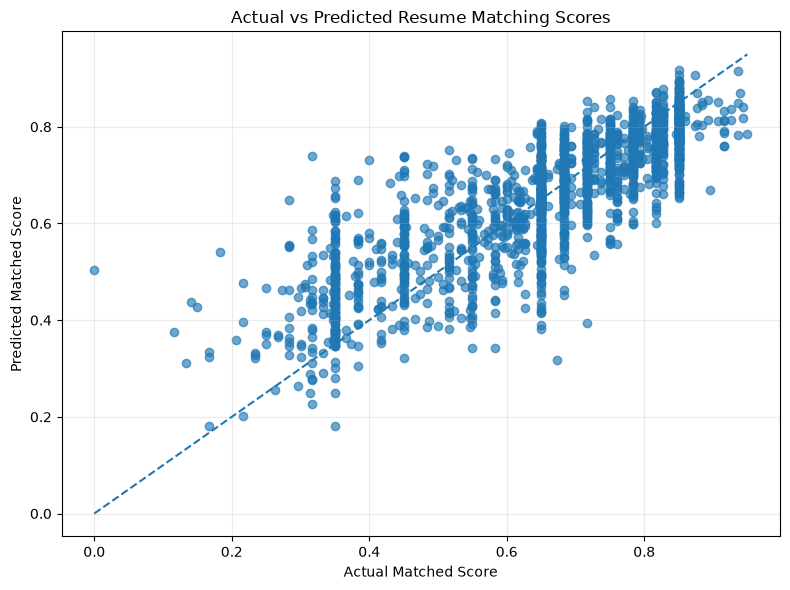

In [19]:
plt.figure(figsize=(8, 6))

plt.scatter(
    actual,
    predictions,
    alpha=0.65
)

minimum = min(
    actual.min(),
    predictions.min()
)

maximum = max(
    actual.max(),
    predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Matched Score")
plt.ylabel("Predicted Matched Score")

plt.title(
    "Actual vs Predicted Resume Matching Scores"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

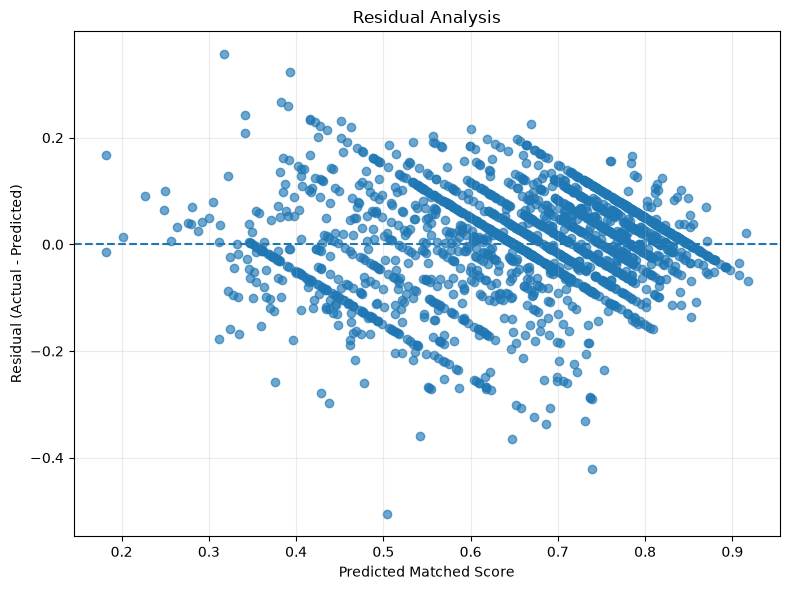

In [21]:
residuals = actual - predictions

plt.figure(figsize=(8, 6))

plt.scatter(
    predictions,
    residuals,
    alpha=0.65
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Matched Score")
plt.ylabel("Residual (Actual - Predicted)")

plt.title("Residual Analysis")

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [23]:
results = test_df.copy()

results["actual_matched_score"] = (
    y_test.to_numpy()
)

results["predicted_matched_score"] = (
    predictions
)

results["absolute_error"] = np.abs(
    results["actual_matched_score"]
    - results["predicted_matched_score"]
)

results = results.sort_values(
    "predicted_matched_score",
    ascending=False
).reset_index(drop=True)

results["rank"] = (
    np.arange(len(results)) + 1
)


display_columns = [
    col for col in [
        "rank",
        "job_position_name",
        "predicted_matched_score",
        "actual_matched_score",
        "absolute_error"
    ]
    if col in results.columns
]

print("TOP 10 CANDIDATE-JOB MATCHES")

display(
    results[display_columns].head(10)
)

TOP 10 CANDIDATE-JOB MATCHES


,rank,job_position_name,predicted_matched_score,actual_matched_score,absolute_error
0,1,asst. manager manger administrative,0.917788,0.850000,0.067788
1,2,full stack developer python react js,0.915949,0.936667,0.020718
2,3,mechanical engineer,0.908092,0.850000,0.058092
3,4,intern generative ai engineering 2d 3d image g...,0.907997,0.873333,0.034663
4,5,senior software engineer,0.897479,0.850000,0.047479
5,6,manager human resource management hrm,0.893214,0.850000,0.043214
6,7,manager human resource management hrm,0.892490,0.850000,0.042490
7,8,executive sr. executive it,0.891964,0.850000,0.041964
8,9,management trainee mechanical,0.891875,0.850000,0.041875
9,10,manager human resource management hrm,0.885916,0.850000,0.035916
